# Notebook 13: is DO weak only because of the binary encoding?

RL-DOHO beat the published DO in 103 of 110 runs. The paper explains this with the encoding: a feature changes only when its coordinate crosses zero, and DO's landing stage pulls every agent to within small Lévy steps (scale s = 0.01) of the elite, so DO keeps reproducing the elite's subset. If that is the reason, DO is a weak baseline partly by construction, and the headline overstates what the intervention layer adds. This notebook tests that directly.

**DO variants (everything else as published):**

| Variant | Change |
|---|---|
| DO, s = 0.1 | landing-stage Lévy step 10× larger |
| DO, s = 1 | landing-stage Lévy step 100× larger |
| DO, sigmoid transfer | feature selected with probability 1/(1+e^(−x)), the standard S-shaped transfer of binary PSO-style optimizers, instead of the deterministic x > 0 |
| RL-DOHO, s = 1 | RL-DOHO whose DO steps use s = 1, the fair comparison if a larger step helps DO |

**References:** the published DO, RL-DOHO and HO, rerun with exactly the Notebook 7/8 code and seeds. They reproduce those runs exactly, and with the earlier caches in your Drive they cost almost nothing.

**Setup:** the Notebook 8 KNN protocol on the ten datasets (five gene-expression, five medical tabular), the **standard budget** (1,020 evaluations, population 20), ten seeds, and the same sparse/dense start as before. The clinical data are excluded because one evaluation there takes about 3.6 s.

**Runtime:** about 1.5–2 hours for all ten datasets, or about an hour each in two parallel sessions (`DATASETS = TABS` in one and `DATASETS = GENE` in the other). The sigmoid variant evaluates a new subset almost every time, so it is the slowest. Each dataset saves to its own file, and every run is saved as soon as it finishes, so rerunning a cell resumes where it stopped. Run sections 7 onwards once, after all datasets are done.

### Hypotheses (fixed before any run of this notebook; every outcome is reported)

These were written after a reviewer asked whether DO is weak only because of the encoding. The variant settings (s = 0.1 and 1, the standard sigmoid) are fixed now and are not tuned.

Pooled two-sided sign tests on fitness over the 100 paired runs (10 datasets × 10 seeds), Holm-corrected over the four:
- **H12a:** RL-DOHO vs DO with s = 0.1.
- **H12b:** RL-DOHO vs DO with s = 1.
- **H12c:** RL-DOHO vs DO with the sigmoid transfer.
- **H12d:** RL-DOHO with s = 1 vs DO with s = 1. Does the layer still help when DO moves freely?

**Reading rule, fixed in advance:**
- **If H12a–c all favour RL-DOHO at Holm p < 0.05:** the advantage over DO is robust to the encoding.
- **If any of them does not:** the paper will state that DO's weakness is partly due to the encoding and step size. In that case, H12d decides whether the layer still adds value over a DO that moves freely.

**Reported without a hypothesis:**
- Each variant against the published DO and against HO.
- Gene and tabular data separately, and test scores.
- How many distinct subsets each variant evaluates, which measures how freely it moves.

A difference below 1e-12 counts as a tie.

In [1]:
# ================= 1. SETUP =================
try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

import os, time, pickle, warnings, urllib.request, gzip, math, hashlib, zipfile
import numpy as np, pandas as pd, scipy.io as sio, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import f1_score, balanced_accuracy_score, precision_score, recall_score, accuracy_score
from scipy.stats import kruskal, spearmanr
warnings.filterwarnings("ignore")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
# ================= 2. CONFIG =================
ROOT      = '/content/drive/MyDrive' if IN_COLAB else '.'
OUT_DIR   = f"{ROOT}/rl_doho_results_v7_encoding"               # results of this notebook
V6_DIR    = f"{ROOT}/rl_doho_results_v6_reward"                 # Notebook 12 (caches reused)
V5_DIR    = f"{ROOT}/rl_doho_results_v5_rl"                     # Notebook 11 (caches reused)
KNN_DIR   = f"{ROOT}/rl_doho_results_v3_knn"                    # Notebook 8 (caches, data, 3x-budget runs)
V2_DIR    = f"{ROOT}/rl_doho_results_v2_genes"                  # Notebook 7 (gene caches, 3x-budget runs)
PREV_DIRS = [f"{ROOT}/rl_doho_results_hd", f"{ROOT}/rl_doho_results_ra", f"{ROOT}/rl_doho_results_baselines_hd", V2_DIR, KNN_DIR, V5_DIR, V6_DIR]
DATA_DIR  = f"{OUT_DIR}/data"
GENE      = ["colon", "ALLAML", "lung", "GLIOMA", "GSE93272"]
TAB       = {"WDBC": "breast_cancer_wisconsin_diagnostic", "Hepatitis": "hepatitis", "Dermatology": "dermatology",
             "SPECTF": "spectf", "Backache": "backache"}
TABS      = list(TAB)
DATASETS  = TABS + GENE              # to run in parallel: e.g. TABS in one Colab session and GENE in another
SEEDS     = list(range(10))
POP_SIZE  = 20
BUDGET    = POP_SIZE * 51            # 1,020: the standard budget, as in the paper
KNN_K, CV_FOLDS, TEST_SIZE = 5, 5, 0.3
ALPHA, BETA = 0.99, 0.01
N_TOP_RA  = 5000
SCORING   = {d: "accuracy" for d in GENE[:4]} | {"GSE93272": "balanced_accuracy"} | {d: "balanced_accuracy" for d in TABS}
VERBOSE   = False

# name -> (algorithm, settings). The first three are the published methods (references).
VARIANTS = {
    "DO":                   ("DO",      dict()),
    "RL-DOHO":              ("RL-DOHO", dict()),
    "HO":                   ("HO",      dict()),
    "DO, s=0.1":            ("DO",      dict(levy_scale=0.1)),
    "DO, s=1":              ("DO",      dict(levy_scale=1.0)),
    "DO, sigmoid transfer": ("DO",      dict(transfer="sigmoid")),
    "RL-DOHO, s=1":         ("RL-DOHO", dict(levy_scale=1.0)),
}
NAMES = list(VARIANTS)

FAST = False                         # True: 2 small datasets x 1 seed with small budgets, only to check the notebook runs
if FAST: DATASETS, SEEDS, BUDGET = ["Hepatitis", "colon"], [0], 200

os.makedirs(DATA_DIR, exist_ok=True)
def init_for(D): return "sparse" if D > 100 else "dense"
def save_pkl(obj, path):
    tmp = path + ".tmp"
    with open(tmp, "wb") as f: pickle.dump(obj, f)
    os.replace(tmp, path)
def load_pkl(path):
    for p in (path, path + ".tmp"):
        if os.path.exists(p):
            try:
                with open(p, "rb") as f: return pickle.load(f)
            except Exception as e: print(f"WARNING: could not read {p} ({e})")
    return {}
print("Output folder:", OUT_DIR, "| datasets:", DATASETS, "| budget per run:", BUDGET)

Output folder: /content/drive/MyDrive/rl_doho_results_v7_encoding | datasets: ['WDBC', 'Hepatitis', 'Dermatology', 'SPECTF', 'Backache', 'colon', 'ALLAML', 'lung', 'GLIOMA', 'GSE93272'] | budget per run: 1020


## 3. Data (the same files as Notebook 8; reused from your Drive when present)

In [3]:
DATA = {}
def first_existing(paths, default): return next((p for p in paths if os.path.exists(p)), default)
URL = "https://raw.githubusercontent.com/jundongl/scikit-feature/master/skfeature/data/{}.mat"
for name in [d for d in DATASETS if d in GENE and d != "GSE93272"]:
    path = first_existing([f"{d}/data/{name}.mat" for d in PREV_DIRS], f"{DATA_DIR}/{name}.mat")
    if not os.path.exists(path): urllib.request.urlretrieve(URL.format(name), path)
    d = sio.loadmat(path); DATA[name] = (d["X"].astype(float), d["Y"].ravel())
if "GSE93272" in DATASETS:
    gpath = first_existing([f"{d}/data/GSE93272_series_matrix.txt.gz" for d in PREV_DIRS], f"{DATA_DIR}/GSE93272_series_matrix.txt.gz")
    if not os.path.exists(gpath):
        urllib.request.urlretrieve("https://ftp.ncbi.nlm.nih.gov/geo/series/GSE93nnn/GSE93272/matrix/GSE93272_series_matrix.txt.gz", gpath)
    chars = []
    with gzip.open(gpath, "rt") as f:
        for line in f:
            if line.startswith("!Sample_geo_accession"): gsm = [v.strip('"') for v in line.rstrip("\n").split("\t")[1:]]
            elif line.startswith("!Sample_characteristics_ch1"): chars.append([v.strip('"') for v in line.rstrip("\n").split("\t")[1:]])
            elif line.startswith("!series_matrix_table_begin"): break
        expr = pd.read_csv(f, sep="\t", index_col=0, comment="!")
    meta = pd.DataFrame(index=gsm)
    for row in chars:
        keys = {v.split(":", 1)[0].strip() for v in row if ":" in v}
        if len(keys) == 1:
            k = keys.pop(); meta[k] = [v.split(":", 1)[1].strip() if ":" in v else None for v in row]
    meta["individual id"] = meta.get("individual id", pd.Series(meta.index, index=meta.index)).fillna(pd.Series(meta.index, index=meta.index))
    meta_k = meta[~meta["individual id"].duplicated(keep="first")]
    DATA["GSE93272"] = (expr[gsm][meta_k.index].T.values.astype(float), (meta_k["disease state"].str.upper() == "RA").astype(int).values)

PMLB = "https://media.githubusercontent.com/media/EpistasisLab/pmlb/master/datasets/{0}/{0}.tsv.gz"
SHA = {"breast_cancer_wisconsin_diagnostic": "b3845ddf3afff808cd6449daa546caf4d8b18f109b7ebb2344990e4c37fea291",
       "hepatitis": "87df1bbfb83b8204093ccd84ed18bb3695220c03aa4096f63a84cc5e136dbc0b",
       "dermatology": "c8852ba546e92249debecd9a897cda3f94fd10872fa13c62eb14ab40e279166e",
       "spectf": "664081130aa48fc189b2e1d3c44332f0b3eb1ee6d31b79af1643c137697677e4",
       "backache": "21d506c397dfeb3edbbbc253b923f59be6edb516689677ebef535296c6c62242"}
for short in [d for d in DATASETS if d in TABS]:
    name = TAB[short]
    path = first_existing([f"{KNN_DIR}/data/{name}.tsv.gz"], f"{DATA_DIR}/{name}.tsv.gz")
    if not os.path.exists(path): urllib.request.urlretrieve(PMLB.format(name), path)
    if hashlib.sha256(open(path, "rb").read()).hexdigest() != SHA[name]: print(f"WARNING: {name} checksum differs from Notebook 8's file")
    df = pd.read_csv(path, sep="\t")
    DATA[short] = (df.drop(columns="target").values.astype(float), pd.factorize(df["target"], sort=True)[0])
pd.DataFrame([{"dataset": n, "samples": X.shape[0], "features": X.shape[1], "classes": len(np.unique(y))} for n, (X, y) in DATA.items()])

,dataset,samples,features,classes
0,colon,62,2000,2
1,ALLAML,72,7129,2
2,lung,203,3312,5
3,GLIOMA,50,4434,4
4,GSE93272,101,54613,2
5,WDBC,569,30,2
6,Hepatitis,155,19,2
7,Dermatology,366,34,6
8,SPECTF,349,44,2
9,Backache,180,32,2


## 4. Fitness and test evaluation (identical to Notebook 8; earlier caches are reused because the fitness is deterministic)

In [4]:
def mask_str(m): return np.packbits(np.asarray(m, dtype=np.uint8)).tobytes().hex()
NEW_EVAL = {}
def use_dataset(name, seed):
    global X_tr, X_te, y_tr, y_te, N_FEATURES, _cache, CV, CUR, SCORE
    X, y = DATA[name]
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=TEST_SIZE, stratify=y, random_state=seed)
    if name == "GSE93272":
        col_mean = np.nanmean(X_tr, axis=0)
        X_tr = np.where(np.isnan(X_tr), col_mean, X_tr); X_te = np.where(np.isnan(X_te), col_mean, X_te)
        top = np.argsort(X_tr.var(axis=0))[-N_TOP_RA:]; X_tr, X_te = X_tr[:, top], X_te[:, top]
    sc = MinMaxScaler().fit(X_tr); X_tr, X_te = sc.transform(X_tr), sc.transform(X_te)
    N_FEATURES = X_tr.shape[1]
    CV = StratifiedKFold(CV_FOLDS, shuffle=True, random_state=seed); SCORE = SCORING[name]; CUR = (name, seed)
    _cache = {}
    for d in PREV_DIRS + [OUT_DIR]:
        c = load_pkl(f"{d}/cache_{name}_s{seed}.pkl")
        if c: _cache.update(c)
def save_cache_now(): save_pkl(_cache, f"{OUT_DIR}/cache_{CUR[0]}_s{CUR[1]}.pkl")

def fitness_function(mask):
    key = mask_str(mask)
    if key in _cache: return _cache[key]["fit"]
    sel = np.flatnonzero(mask)
    if len(sel) == 0:
        _cache[key] = {"fit": 1.0, "acc": 0.0}; return 1.0
    t0 = time.perf_counter()
    acc = cross_val_score(KNeighborsClassifier(KNN_K), X_tr[:, sel], y_tr, cv=CV, scoring=SCORE).mean()
    f = ALPHA * (1 - acc) + BETA * len(sel) / len(mask)
    _cache[key] = {"fit": f, "acc": acc}
    c = NEW_EVAL.setdefault(CUR[0], [0, 0.0]); c[0] += 1; c[1] += time.perf_counter() - t0
    return f

def test_metrics(mask):
    sel = np.flatnonzero(mask)
    p = KNeighborsClassifier(KNN_K).fit(X_tr[:, sel], y_tr).predict(X_te[:, sel])
    acc = balanced_accuracy_score(y_te, p) if SCORE == "balanced_accuracy" else accuracy_score(y_te, p)
    return {"test_acc": float(acc), "test_prec": float(precision_score(y_te, p, average="macro", zero_division=0)),
            "test_rec": float(recall_score(y_te, p, average="macro", zero_division=0)), "test_f1": float(f1_score(y_te, p, average="macro"))}
print("Fitness ready.")

Fitness ready.


## 5. Algorithms: the Notebook 8 code, unchanged, plus the DO variants (Lévy step scale, sigmoid transfer)

In [5]:
# ===================== RL-DOHO v2: shared algorithm code =====================
# Every method gets the same number of FITNESS EVALUATIONS (not iterations), because the
# published HO evaluates about 3N candidates per iteration while DO evaluates N.
# Encoding: continuous position x in [LB, UB]^D, feature j selected if sigmoid(x_j) > 0.5 (i.e. x_j > 0).
import math, time
import numpy as np, pandas as pd

LB, UB = -3.0, 3.0

class BudgetExhausted(Exception):
    pass

def binarize(x):
    return (np.asarray(x) > 0).astype(np.int8)          # identical to sigmoid(x) > 0.5

def mkey(mask):
    return np.packbits(np.asarray(mask, dtype=np.uint8)).tobytes()

class Problem:
    """Wraps a (cached, deterministic) fitness function and enforces the evaluation budget.
    Also records the time spent inside the fitness function (fsec) and the number of distinct
    subsets evaluated (len(seen)), so the algorithm's own overhead can be separated from fitness cost."""
    def __init__(self, fitness_fn, D, budget):
        self.fitness_fn, self.D, self.budget, self.calls = fitness_fn, D, budget, 0
        self.fsec, self.seen = 0.0, set()
    def left(self):
        return self.budget - self.calls
    def f(self, mask):
        if self.calls >= self.budget:
            raise BudgetExhausted
        self.calls += 1
        m = np.asarray(mask, dtype=np.int8); self.seen.add(mkey(m))
        t0 = time.perf_counter(); v = float(self.fitness_fn(m)); self.fsec += time.perf_counter() - t0
        return v
    def fx(self, x):
        return self.f(binarize(x))

# ------------------------------------------------------------------ initialisation
def init_population(rng, N, D, mode="dense"):
    """dense : x ~ U(-1, 1)  -> each feature selected with probability 0.5 (as in Notebooks 1-5).
       sparse: agent i keeps a fraction p_i ~ log-uniform[min(10/D, 0.1), 0.1] of the features
               (used when D > 100: ten features up to 10% of them)."""
    if mode == "dense":
        return rng.uniform(-1, 1, (N, D))
    lo, hi = math.log(min(10.0 / D, 0.1)), math.log(0.1)
    X = np.empty((N, D))
    for i in range(N):
        p = math.exp(rng.uniform(lo, hi))
        sel = rng.random(D) < p
        if not sel.any():
            sel[rng.integers(D)] = True
        X[i] = np.where(sel, rng.uniform(0.1, 1.0, D), -rng.uniform(0.1, 1.0, D))
    return X

def random_position(rng, D, mode):
    return init_population(rng, 1, D, mode)[0]

# ------------------------------------------------------------------ Levy flight (Mantegna)
def levy(rng, shape, beta=1.5):
    num = math.gamma(1 + beta) * math.sin(math.pi * beta / 2)
    den = math.gamma((1 + beta) / 2) * beta * 2 ** ((beta - 1) / 2)
    sigma = (num / den) ** (1 / beta)
    u = rng.normal(0, sigma, shape); v = rng.normal(0, 1, shape)
    return u / np.abs(v) ** (1 / beta)

def lognpdf(x):                                          # lognormal pdf, mu = 0, sigma = 1
    x = np.maximum(x, 1e-300)
    return np.exp(-np.log(x) ** 2 / 2) / (x * math.sqrt(2 * math.pi))

# ------------------------------------------------------------------ Dandelion Optimizer (Zhao et al., 2022)
def do_move(rng, X, elite, t, T):
    """One full DO iteration: rising (Eqs. 2-8), descending (Eqs. 10-11), landing (Eqs. 12-14).
    Returns the new population; the caller evaluates it (N evaluations)."""
    N, D = X.shape
    T = max(T, 2); t = min(max(t, 1), T)
    alpha = rng.random() * ((t / T) ** 2 - 2 * t / T + 1)                     # Eq. 4: adaptive step
    a = 1.0 / (T ** 2 - 2 * T + 1); b = -2 * a; c = 1 - a - b
    k = 1 - rng.random() * (c + a * t ** 2 + b * t)                          # Eq. 8 (k with q)
    # --- rising stage
    if rng.standard_normal() < 1.5:                                          # clear weather
        lamb = np.abs(rng.standard_normal((N, D)))
        theta = (2 * rng.random(N) - 1) * math.pi
        r = 1 / np.exp(theta); vx = r * np.cos(theta); vy = r * np.sin(theta)
        Xs = rng.uniform(LB, UB, (N, D))                                     # Eq. 3: random position
        X1 = X + alpha * (vx * vy)[:, None] * lognpdf(lamb) * (Xs - X)       # Eq. 2
    else:                                                                    # rainy weather
        X1 = X * k                                                           # Eq. 7
    X1 = np.clip(X1, LB, UB)
    # --- descending stage (Brownian motion around the population mean)
    beta = rng.standard_normal((N, D))
    Xm = X1.mean(axis=0)                                                     # Eq. 11
    X2 = np.clip(X1 - beta * alpha * (Xm - beta * alpha * X1), LB, UB)      # Eq. 10
    # --- landing stage (Levy flight around the elite)
    step = 0.01 * levy(rng, (N, D))                                          # Eq. 13, s = 0.01, beta = 1.5
    delta = 2 * t / T                                                        # Eq. 14
    X3 = elite + step * alpha * (elite - X2 * delta)                         # Eq. 12
    return np.clip(X3, LB, UB)

# ------------------------------------------------------------------ Hippopotamus Optimization (Amiri et al., 2024)
def ho_iteration(rng, X, F, dominant, t, T, prob, on_eval):
    """One full HO iteration with greedy selection, updating X, F in place.
    Phase 1 (first half): male + female/immature candidates (Eqs. 3-9)      -> 2 evaluations per agent
    Phase 2 (second half): predator + defence candidate (Eqs. 10-16)        -> 2 evaluations per agent
    Phase 3 (all agents): escape within shrinking local bounds (Eqs. 17-19) -> 1 evaluation per agent
    on_eval(x, f) is called for every evaluated candidate that is a hippopotamus position."""
    N, D = X.shape
    half = N // 2
    T = max(T, 1); t = min(max(t, 1), T)
    for i in range(half):
        I1, I2 = rng.integers(1, 3, 2); rho = rng.integers(0, 2, 2)
        g = int(rng.integers(1, N + 1)); grp = rng.choice(N, g, replace=False)
        MG = X[grp].mean(axis=0)
        h = [I2 * rng.random(D) + (1 - rho[0]), 2 * rng.random(D) - 1, rng.random(D),
             I1 * rng.random(D) + (1 - rho[1]), rng.random()]                  # Eq. 4
        h1, h2 = h[rng.integers(5)], h[rng.integers(5)]
        x_m = np.clip(X[i] + rng.random() * (dominant - I1 * X[i]), LB, UB)     # Eq. 3 (male)
        if math.exp(-t / T) > 0.6:                                            # Eq. 5
            x_f = X[i] + h1 * (dominant - I2 * MG)                            # Eq. 6
        elif rng.random() > 0.5:
            x_f = X[i] + h2 * (MG - dominant)                                 # Eq. 7
        else:
            x_f = rng.uniform(LB, UB, D)
        x_f = np.clip(x_f, LB, UB)
        for x in (x_m, x_f):                                                  # Eqs. 8-9: greedy
            f = prob.fx(x); on_eval(x, f)
            if f < F[i]: X[i], F[i] = x, f
    for i in range(half, N):
        pred = rng.uniform(LB, UB, D)                                         # Eq. 10
        f_pred = prob.fx(pred)
        dist = np.abs(pred - X[i]) + 1e-12                                    # Eq. 11
        b_, c_, d_ = rng.uniform(2, 4), rng.uniform(1, 1.5), rng.uniform(2, 3)
        l_ = rng.uniform(-2 * math.pi, 2 * math.pi)                           # 2*pi*g with g in [-1, 1]
        RL = 0.05 * levy(rng, D)                                              # Eq. 13
        if F[i] > f_pred:
            x = RL * pred + (b_ / (c_ - d_ * math.cos(l_))) * (1 / dist)      # Eq. 12, case 1
        else:
            x = RL * pred + (b_ / (c_ - d_ * math.cos(l_))) * (1 / (2 * dist + rng.random(D)))
        x = np.clip(x, LB, UB)
        f = prob.fx(x); on_eval(x, f)
        if f < F[i]: X[i], F[i] = x, f                                        # Eqs. 15-16
    lo, hi = LB / t, UB / t                                                   # Eq. 17: local bounds
    for i in range(N):
        s = [2 * rng.random(D) - 1, rng.random(), rng.standard_normal()][rng.integers(3)]   # Eq. 19
        x = np.clip(X[i] + rng.random() * (lo + s * (hi - lo)), LB, UB)      # Eq. 18
        f = prob.fx(x); on_eval(x, f)
        if f < F[i]: X[i], F[i] = x, f                                        # Eq. 20

# ------------------------------------------------------------------ run bookkeeping
class Tracker:
    """Tracks the best subset found and logs one row per iteration."""
    def __init__(self, name, prob, verbose=False, tie_eps=0.0):
        self.name, self.prob, self.verbose, self.tie_eps = name, prob, verbose, tie_eps
        self.best_f, self.best_x, self.best_m = np.inf, None, None
        self.rows, self.t0 = [], time.time()
    def better(self, f, nf):
        if self.best_m is None: return True
        bf, bn = self.best_f, int(self.best_m.sum())
        e = self.tie_eps
        if e <= 0: return f < bf
        return f < bf - e or (abs(f - bf) <= e and (nf < bn or (nf == bn and f < bf)))
    def offer(self, x, f, mask=None):
        m = binarize(x) if mask is None else mask
        if self.better(f, int(m.sum())):
            self.best_f, self.best_x, self.best_m = f, (None if x is None else np.array(x, float)), m.copy()
            return True
        return False
    def log(self, it, action, F=None, reward=None):
        row = dict(iter=it, evals=self.prob.calls, action=action, best=self.best_f,
                   n_feats=int(self.best_m.sum()), pop_mean=(float(np.mean(F)) if F is not None else np.nan),
                   reward=reward, sec=time.time() - self.t0)
        self.rows.append(row)
        if self.verbose:
            rw = "" if reward is None else f"  r={reward:.3f}"
            print(f"  {self.name:<16} it {it:>3}  evals {self.prob.calls:>5}/{self.prob.budget}  {action:<10}"
                  f" best {self.best_f:.5f}  feats {row['n_feats']:>5}{rw}")
    def result(self):
        return {"mask": self.best_m, "fit": self.best_f, "hist": pd.DataFrame(self.rows)}

def _start(prob, rng, N, init, tr):
    X = init_population(rng, N, prob.D, init)
    F = np.array([prob.fx(x) for x in X])
    for x, f in zip(X, F): tr.offer(x, f)
    tr.log(0, "init", F)
    return X, F

# ------------------------------------------------------------------ DO, HO, DOHO (published update rules)
def run_do(prob, N, seed, init="dense", verbose=False):
    rng = np.random.default_rng(seed); tr = Tracker("DO", prob, verbose)
    T = max(2, (prob.budget - N) // N)
    try:
        X, F = _start(prob, rng, N, init, tr)
        for t in range(1, T + 1):
            X = do_move(rng, X, tr.best_x, t, T)
            F = np.array([prob.fx(x) for x in X])
            for x, f in zip(X, F): tr.offer(x, f)
            tr.log(t, "DO", F)
    except BudgetExhausted:
        pass
    return tr.result()

def run_ho(prob, N, seed, init="dense", verbose=False):
    rng = np.random.default_rng(seed); tr = Tracker("HO", prob, verbose)
    T = max(1, math.ceil((prob.budget - N) / (3 * N)))
    try:
        X, F = _start(prob, rng, N, init, tr)
        for t in range(1, T + 1):
            dom = X[np.argmin(F)].copy()
            ho_iteration(rng, X, F, dom, t, T, prob, tr.offer)
            tr.log(t, "HO", F)
    except BudgetExhausted:
        if tr.rows and tr.rows[-1]["evals"] != prob.calls: tr.log(len(tr.rows), "HO (partial)", F)
    return tr.result()

def run_doho(prob, N, seed, init="dense", verbose=False):
    """Fixed switch: published DO for the first half of the budget, then published HO."""
    rng = np.random.default_rng(seed); tr = Tracker("DOHO", prob, verbose)
    half_budget = prob.budget // 2
    T1 = max(2, (half_budget - N) // N); T2 = max(1, math.ceil((prob.budget - half_budget) / (3 * N)))
    it = 0
    try:
        X, F = _start(prob, rng, N, init, tr)
        for t in range(1, T1 + 1):
            if prob.calls + N > half_budget: break
            X = do_move(rng, X, tr.best_x, t, T1)
            F = np.array([prob.fx(x) for x in X])
            for x, f in zip(X, F): tr.offer(x, f)
            it += 1; tr.log(it, "DO", F)
        for t in range(1, T2 + 1):
            ho_iteration(rng, X, F, X[np.argmin(F)].copy(), t, T2, prob, tr.offer)
            it += 1; tr.log(it, "HO", F)
    except BudgetExhausted:
        pass
    return tr.result()

# ------------------------------------------------------------------ controllers
class UCB1:
    def __init__(self, n_arms, seed, c=1.0):
        self.rng = np.random.default_rng(seed + 7919); self.c = c
        self.n = np.zeros(n_arms); self.v = np.zeros(n_arms)
    def choose(self, state=None):
        untried = np.flatnonzero(self.n == 0)
        if len(untried): return int(self.rng.choice(untried)), "i"
        ucb = self.v + self.c * np.sqrt(2 * np.log(self.n.sum()) / self.n)
        return int(self.rng.choice(np.flatnonzero(np.isclose(ucb, ucb.max())))), "u"
    def update(self, a, r):
        self.n[a] += 1; self.v[a] += (r - self.v[a]) / self.n[a]
    def finish(self):
        pass

class RandomArm(UCB1):
    def choose(self, state=None): return int(self.rng.integers(len(self.n))), "r"

class FixedArm(UCB1):
    def __init__(self, n_arms, seed, arm=0):
        super().__init__(n_arms, seed); self.arm = arm
    def choose(self, state=None): return self.arm, "f"

N_STATES = 6
def controller_state(calls, budget, last_gain):
    """State for the Q-learning controller: budget phase (first, second, last third) x whether the
    previous intervention improved the best subset (0/1) -> 6 states."""
    phase = min(2, int(3 * calls / budget))
    return 2 * phase + (1 if last_gain > 0 else 0)

class QLearn(UCB1):
    """Tabular one-step Q-learning over the arms. Epsilon-greedy (eps = 0.2), learning rate 0.3,
    discount 0.5, Q initialised at 0. The next state is the state at the next decision; the last
    decision of a run is updated without bootstrapping. Settings fixed in advance, not tuned."""
    def __init__(self, n_arms, seed, n_states=N_STATES, lr=0.3, gamma=0.5, eps=0.2):
        super().__init__(n_arms, seed)
        self.Q = np.zeros((n_states, n_arms)); self.lr, self.gamma, self.eps = lr, gamma, eps
        self.pending, self.s = None, 0
    def choose(self, state=0):
        if self.pending is not None:
            s, a, r = self.pending
            self.Q[s, a] += self.lr * (r + self.gamma * self.Q[state].max() - self.Q[s, a]); self.pending = None
        self.s = state
        if self.rng.random() < self.eps:
            return int(self.rng.integers(self.Q.shape[1])), "e"
        q = self.Q[state]
        return int(self.rng.choice(np.flatnonzero(np.isclose(q, q.max())))), "q"
    def update(self, a, r):
        self.n[a] += 1; self.pending = (self.s, a, r)
    def finish(self):
        if self.pending is not None:
            s, a, r = self.pending; self.Q[s, a] += self.lr * (r - self.Q[s, a]); self.pending = None

CONTROLLERS = {"ucb": UCB1, "random": RandomArm, "qlearn": QLearn}

ARMS = ("PERTURB", "RESTART", "DO", "HO")

# ------------------------------------------------------------------ RL-DOHO v2
def run_rldoho(prob, N, seed, init="dense", verbose=False, controller="ucb", reward="gain",
               kappa=2, tie_eps=1e-3, k_max=3, tabu_tries=20, intervene=True, name="RL-DOHO"):
    """DO (published) while the best improves; after `kappa` iterations without an accepted improvement,
    a controller picks one arm: PERTURB / RESTART (worse half, tabu) or one published DO / HO iteration.
    reward="gain": 0.8 * min(1, g / g_max) + 0.2 * share, where g = fitness gain of the best per evaluation
                   spent (parsimony-only moves give g = 0) and g_max = largest g seen so far in the run.
    reward="old" : 1 if the best changed, otherwise 0.2 * share (Notebooks 1-5)."""
    rng = np.random.default_rng(seed); D = prob.D
    tr = Tracker(name, prob, verbose, tie_eps=tie_eps)
    ctrl = CONTROLLERS.get(controller)
    ctrl = ctrl(len(ARMS), seed) if ctrl else FixedArm(len(ARMS), seed, arm=ARMS.index(controller))
    T_do = max(2, (prob.budget - N) // N); T_ho = max(1, math.ceil((prob.budget - N) / (3 * N)))
    def sched(T):                     # DO / HO schedules follow the share of the budget already spent
        return min(T, max(1, math.ceil(T * prob.calls / prob.budget)))
    tabu = set(); g_max = 0.0; stag = 0; it = 0; last_gain = 0.0
    arm_log = []
    def offer(x, f):
        tabu.add(mkey(binarize(x)))
        return tr.offer(x, f)
    def tabu_draw(make):
        for _ in range(tabu_tries):
            x = np.clip(make(), LB, UB)
            if mkey(binarize(x)) not in tabu: break
        return x
    try:
        X = init_population(rng, N, D, init)
        F = np.array([prob.fx(x) for x in X])
        for x, f in zip(X, F): offer(x, f)
        tr.log(0, "init", F)
        while prob.left() > 0:
            it += 1
            prev_best, prev_feats, prev_med, calls0 = tr.best_f, int(tr.best_m.sum()), float(np.median(F)), prob.calls
            changed_before = (tr.best_f, int(tr.best_m.sum()))
            if not intervene or stag < kappa:
                arm, how = None, None
                X = do_move(rng, X, tr.best_x, sched(T_do), T_do)
                F = np.array([prob.fx(x) for x in X])
                for x, f in zip(X, F): offer(x, f)
                moved = np.arange(N)
            else:
                arm, how = ctrl.choose(controller_state(prob.calls, prob.budget, last_gain)); a = ARMS[arm]
                if a == "DO":
                    X = do_move(rng, X, tr.best_x, sched(T_do), T_do)
                    F = np.array([prob.fx(x) for x in X])
                    for x, f in zip(X, F): offer(x, f)
                    moved = np.arange(N)
                elif a == "HO":
                    F_before = F.copy()
                    ho_iteration(rng, X, F, X[np.argmin(F)].copy(), sched(T_ho), T_ho, prob, offer)
                    moved = np.flatnonzero(F != F_before)
                else:
                    worst = np.argsort(F)[N // 2:]
                    for i in worst:
                        if a == "PERTURB":
                            def make():
                                x = tr.best_x.copy(); k = int(rng.integers(1, k_max + 1))
                                j = rng.choice(D, k, replace=False)
                                x[j] = -np.sign(x[j] + 1e-12) * rng.uniform(0.5, 2.0, k)
                                return x
                        else:
                            make = lambda: random_position(rng, D, init)
                        X[i] = tabu_draw(make)
                        F[i] = prob.fx(X[i]); offer(X[i], F[i])
                    moved = worst
            cost = max(1, prob.calls - calls0)
            changed = (tr.best_f, int(tr.best_m.sum())) != changed_before
            stag = 0 if changed else stag + 1
            g = max(0.0, prev_best - tr.best_f) / cost
            g_max = max(g_max, g)
            if arm is None:
                tr.log(it, "explore", F)
            else:
                share = float(np.mean(F[moved] < prev_med)) if len(moved) else 0.0
                if reward == "gain":
                    r = 0.8 * (min(1.0, g / g_max) if g_max > 0 else 0.0) + 0.2 * share
                else:
                    r = 1.0 if changed else 0.2 * share
                ctrl.update(arm, r); last_gain = prev_best - tr.best_f
                arm_log.append((it, ARMS[arm], how, r, prev_best - tr.best_f, cost))
                tr.log(it, f"{ARMS[arm]}({how})", F, reward=r)
    except BudgetExhausted:
        pass
    ctrl.finish()
    res = tr.result()
    res["arms"] = pd.DataFrame(arm_log, columns=["iter", "arm", "how", "reward", "gain", "cost"])
    return res

# ------------------------------------------------------------------ GA, BPSO, BGWO (same budget and initial population)
def run_ga(prob, N, seed, init="dense", verbose=False, pc=0.9, tour=3):
    rng = np.random.default_rng(seed); tr = Tracker("GA", prob, verbose); D = prob.D; pm = 1.0 / D
    try:
        X, F = _start(prob, rng, N, init, tr)
        M = binarize(X); it = 0
        while True:
            def pick():
                idx = rng.choice(N, tour, replace=False); return M[idx[np.argmin(F[idx])]]
            new = [tr.best_m.copy()]
            while len(new) < N:
                p1, p2 = pick(), pick()
                if rng.random() < pc:
                    cm = rng.random(D) < 0.5; kids = [np.where(cm, p1, p2), np.where(cm, p2, p1)]
                else:
                    kids = [p1.copy(), p2.copy()]
                for c in kids:
                    c = np.where(rng.random(D) < pm, 1 - c, c).astype(np.int8)
                    if len(new) < N: new.append(c)
            M = np.array(new, dtype=np.int8)
            F = np.empty(N)
            for i in range(N):
                F[i] = prob.f(M[i]); tr.offer(None, F[i], mask=M[i])
            it += 1; tr.log(it, "gen", F)
    except BudgetExhausted:
        pass
    return tr.result()

def run_bpso(prob, N, seed, init="dense", verbose=False, c1=2.0, c2=2.0, vmax=6.0):
    rng = np.random.default_rng(seed); tr = Tracker("BPSO", prob, verbose); D = prob.D
    T = max(2, (prob.budget - N) // N)
    try:
        X0, F = _start(prob, rng, N, init, tr)
        X = binarize(X0); V = rng.uniform(-1, 1, (N, D))
        if init == "sparse":                      # start velocities consistent with the sparse masks
            V = np.where(X == 1, rng.uniform(0, 1, (N, D)), rng.uniform(-6, -1, (N, D)))
        pb, pbf = X.copy(), F.copy()
        for t in range(1, T + 1):
            w = 0.9 - 0.5 * t / T
            r1, r2 = rng.random((N, D)), rng.random((N, D))
            V = np.clip(w * V + c1 * r1 * (pb - X) + c2 * r2 * (tr.best_m - X), -vmax, vmax)
            X = (rng.random((N, D)) < 1 / (1 + np.exp(-V))).astype(np.int8)
            F = np.empty(N)
            for i in range(N):
                F[i] = prob.f(X[i]); tr.offer(None, F[i], mask=X[i])
            imp = F < pbf; pb[imp] = X[imp]; pbf[imp] = F[imp]
            tr.log(t, "move", F)
    except BudgetExhausted:
        pass
    return tr.result()

def run_bgwo(prob, N, seed, init="dense", verbose=False):
    rng = np.random.default_rng(seed); tr = Tracker("BGWO", prob, verbose); D = prob.D
    T = max(2, (prob.budget - N) // N)
    try:
        X, F = _start(prob, rng, N, init, tr)
        for t in range(1, T + 1):
            a = 2 - 2 * t / T
            leaders = X[np.argsort(F)[:3]].copy()
            new = np.empty_like(X)
            for i in range(N):
                xs = [Lp - (2 * a * rng.random(D) - a) * np.abs(2 * rng.random(D) * Lp - X[i]) for Lp in leaders]
                new[i] = np.clip(np.mean(xs, axis=0), LB, UB)
            X = new
            F = np.array([prob.fx(x) for x in X])
            for x, f in zip(X, F): tr.offer(x, f)
            tr.log(t, "move", F)
    except BudgetExhausted:
        pass
    return tr.result()


# ------------------------------------------------------------------ stagnation-triggered add-on for any base optimiser
def ga_generation(rng, X, F, best_m, prob, offer, pc=0.9, tour=3):
    """One GA generation (tournament 3, uniform crossover, bit-flip 1/D, elitism of 1) on the masks of X.
    Children are stored as positions +-1 so that the shared PERTURB / RESTART operators can act on them."""
    N, D = X.shape; M = binarize(X); pm = 1.0 / D
    def pick():
        idx = rng.choice(N, tour, replace=False); return M[idx[np.argmin(F[idx])]]
    new = [best_m.copy()]
    while len(new) < N:
        p1, p2 = pick(), pick()
        if rng.random() < pc:
            cm = rng.random(D) < 0.5; kids = [np.where(cm, p1, p2), np.where(cm, p2, p1)]
        else:
            kids = [p1.copy(), p2.copy()]
        for c in kids:
            c = np.where(rng.random(D) < pm, 1 - c, c).astype(np.int8)
            if len(new) < N: new.append(c)
    X = np.where(np.array(new) == 1, 1.0, -1.0)
    F = np.empty(N)
    for i in range(N):
        F[i] = prob.fx(X[i]); offer(X[i], F[i])
    return X, F

def run_si(prob, N, seed, base="GA", init="dense", verbose=False, controller="ucb", reward="gain",
           kappa=2, tie_eps=1e-3, k_max=3, tabu_tries=20, name=None):
    """The RL-DOHO intervention layer around another optimiser ("GA" or "HO"): the base optimiser runs while
    the best subset improves; after `kappa` stalled iterations the controller picks PERTURB, RESTART or one
    base iteration, with the same gain reward, tabu memory and tie-break as RL-DOHO. Used to test whether the
    interventions help other optimisers too."""
    rng = np.random.default_rng(seed); D = prob.D; arms = ("PERTURB", "RESTART", base)
    tr = Tracker(name or f"{base}+SI", prob, verbose, tie_eps=tie_eps)
    ctrl = CONTROLLERS[controller](len(arms), seed)
    T_ho = max(1, math.ceil((prob.budget - N) / (3 * N)))
    sched = lambda T: min(T, max(1, math.ceil(T * prob.calls / prob.budget)))
    tabu = set(); g_max = 0.0; stag = 0; it = 0; last_gain = 0.0; arm_log = []
    def offer(x, f):
        tabu.add(mkey(binarize(x))); return tr.offer(x, f)
    def base_step(X, F):
        if base == "GA":
            X, F = ga_generation(rng, X, F, tr.best_m, prob, offer); return X, F, np.arange(N)
        F0 = F.copy(); ho_iteration(rng, X, F, X[np.argmin(F)].copy(), sched(T_ho), T_ho, prob, offer)
        return X, F, np.flatnonzero(F != F0)
    try:
        X = init_population(rng, N, D, init)
        F = np.array([prob.fx(x) for x in X])
        for x, f in zip(X, F): offer(x, f)
        tr.log(0, "init", F)
        while prob.left() > 0:
            it += 1
            prev_best, prev_med, calls0 = tr.best_f, float(np.median(F)), prob.calls
            before = (tr.best_f, int(tr.best_m.sum()))
            if stag < kappa:
                arm = None; X, F, moved = base_step(X, F)
            else:
                arm, how = ctrl.choose(controller_state(prob.calls, prob.budget, last_gain)); a = arms[arm]
                if a == base:
                    X, F, moved = base_step(X, F)
                else:
                    worst = np.argsort(F)[N // 2:]
                    for i in worst:
                        if a == "PERTURB":
                            def make():
                                x = tr.best_x.copy(); k = int(rng.integers(1, k_max + 1))
                                j = rng.choice(D, k, replace=False)
                                x[j] = -np.sign(x[j] + 1e-12) * rng.uniform(0.5, 2.0, k)
                                return x
                        else:
                            make = lambda: random_position(rng, D, init)
                        for _ in range(tabu_tries):
                            x = np.clip(make(), LB, UB)
                            if mkey(binarize(x)) not in tabu: break
                        X[i] = x; F[i] = prob.fx(x); offer(x, F[i])
                    moved = worst
            cost = max(1, prob.calls - calls0)
            changed = (tr.best_f, int(tr.best_m.sum())) != before
            stag = 0 if changed else stag + 1
            g = max(0.0, prev_best - tr.best_f) / cost; g_max = max(g_max, g)
            if arm is None:
                tr.log(it, "explore", F)
            else:
                share = float(np.mean(F[moved] < prev_med)) if len(moved) else 0.0
                r = (0.8 * (min(1.0, g / g_max) if g_max > 0 else 0.0) + 0.2 * share) if reward == "gain" \
                    else (1.0 if changed else 0.2 * share)
                ctrl.update(arm, r); last_gain = prev_best - tr.best_f
                arm_log.append((it, arms[arm], how, r, prev_best - tr.best_f, cost))
                tr.log(it, f"{arms[arm]}({how})", F, reward=r)
    except BudgetExhausted:
        pass
    ctrl.finish()
    res = tr.result(); res["arms"] = pd.DataFrame(arm_log, columns=["iter", "arm", "how", "reward", "gain", "cost"])
    return res

def run_ga_si(prob, N, seed, init="dense", verbose=False, **kw): return run_si(prob, N, seed, "GA", init, verbose, **kw)
def run_ho_si(prob, N, seed, init="dense", verbose=False, **kw): return run_si(prob, N, seed, "HO", init, verbose, **kw)

# ------------------------------------------------------------------ filter / embedded baselines (as in Notebooks 4 and 5)
# Each ranks features on the training data only; k is then chosen by the same fitness (CV on training data).
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import mutual_info_classif

def rank_lasso(X, y, seed, k_max):
    Xs = (X - X.mean(0)) / (X.std(0) + 1e-12)
    m = LogisticRegression(penalty="l1", solver="saga", C=0.5, max_iter=3000, random_state=seed).fit(Xs, y)
    return np.argsort(-np.abs(m.coef_).sum(0), kind="stable")

def rank_mrmr(X, y, seed, k_max):
    rel = mutual_info_classif(X, y, random_state=seed)
    Xs = (X - X.mean(0)) / (X.std(0) + 1e-12); n = len(Xs)
    sel = [int(np.argmax(rel))]; red = np.zeros(X.shape[1])
    for _ in range(min(k_max, X.shape[1], 2000) - 1):
        red += np.abs(Xs.T @ Xs[:, sel[-1]]) / n
        score = rel - red / len(sel); score[sel] = -np.inf
        sel.append(int(np.argmax(score)))
    rest = [j for j in np.argsort(-rel) if j not in set(sel)]
    return np.array(sel + rest)

def rank_relieff(X, y, seed, k_max, m=500, k=10):
    rng = np.random.default_rng(seed)
    Xn = (X - X.min(0)) / (X.max(0) - X.min(0) + 1e-12)
    classes, counts = np.unique(y, return_counts=True); prior = dict(zip(classes, counts / len(y)))
    idx = rng.choice(len(Xn), min(m, len(Xn)), replace=False); W = np.zeros(Xn.shape[1])
    for i in idx:
        d = np.abs(Xn - Xn[i]).sum(1); d[i] = np.inf
        for c in classes:
            cand = np.flatnonzero(y == c); cand = cand[cand != i]
            if len(cand) == 0: continue
            nn = cand[np.argsort(d[cand])[:k]]
            diff = np.abs(Xn[nn] - Xn[i]).mean(0)
            if c == y[i]: W -= diff / len(idx)
            else: W += prior[c] / (1 - prior[y[i]]) * diff / len(idx)
    return np.argsort(-W, kind="stable")

RANKERS = {"LASSO": rank_lasso, "mRMR": rank_mrmr, "ReliefF": rank_relieff}

def k_grid(D):
    if D <= 40: return list(range(1, D + 1))
    return sorted({k for k in [5, 10, 20, 50, 100, 200, 500, 1000, 2000, D] if k <= D})

def run_filter(name, seed, X_rank, y_rank, fitness_fn, D):
    """Returns (mask, fitness, chosen k). 'All features' keeps everything."""
    if name == "All features":
        m = np.ones(D, np.int8); return m, fitness_fn(m), D
    ks = k_grid(D); order = RANKERS[name](np.asarray(X_rank, float), np.asarray(y_rank), seed, max(ks))
    best = None
    for k in ks:
        m = np.zeros(D, np.int8); m[order[:k]] = 1
        f = fitness_fn(m)
        if best is None or f < best[1] - 1e-12: best = (m, f, k)
    return best

RUNNERS = {"DO": run_do, "HO": run_ho, "DOHO": run_doho, "RL-DOHO": run_rldoho,
           "GA": run_ga, "BPSO": run_bpso, "BGWO": run_bgwo, "GA+SI": run_ga_si, "HO+SI": run_ho_si}

# ===================== Notebook 13: is DO weak only because of the binary encoding? =====================
# Two changes to the published DO, each switchable; with the defaults (levy_scale=0.01, transfer="threshold")
# run_do_x reproduces run_do exactly (same random numbers, same subsets, same result).
#   levy_scale : the landing-stage step size s in Eq. 13 (published s = 0.01). Larger s lets agents leave the elite.
#   transfer   : "threshold" = feature selected if x > 0 (used throughout the paper, deterministic);
#                "sigmoid"   = feature selected with probability 1 / (1 + exp(-x)), the standard S-shaped
#                              transfer function of binary PSO-style optimizers (stochastic).

def do_move_x(rng, X, elite, t, T, levy_scale=0.01):
    """do_move with the landing-stage Levy step scale as a parameter (identical to do_move at 0.01)."""
    N, D = X.shape
    T = max(T, 2); t = min(max(t, 1), T)
    alpha = rng.random() * ((t / T) ** 2 - 2 * t / T + 1)
    a = 1.0 / (T ** 2 - 2 * T + 1); b = -2 * a; c = 1 - a - b
    k = 1 - rng.random() * (c + a * t ** 2 + b * t)
    if rng.standard_normal() < 1.5:
        lamb = np.abs(rng.standard_normal((N, D)))
        theta = (2 * rng.random(N) - 1) * math.pi
        r = 1 / np.exp(theta); vx = r * np.cos(theta); vy = r * np.sin(theta)
        Xs = rng.uniform(LB, UB, (N, D))
        X1 = X + alpha * (vx * vy)[:, None] * lognpdf(lamb) * (Xs - X)
    else:
        X1 = X * k
    X1 = np.clip(X1, LB, UB)
    beta = rng.standard_normal((N, D))
    Xm = X1.mean(axis=0)
    X2 = np.clip(X1 - beta * alpha * (Xm - beta * alpha * X1), LB, UB)
    step = levy_scale * levy(rng, (N, D))
    delta = 2 * t / T
    X3 = elite + step * alpha * (elite - X2 * delta)
    return np.clip(X3, LB, UB)

def run_do_x(prob, N, seed, init="dense", verbose=False, levy_scale=0.01, transfer="threshold", name="DO-x"):
    rng = np.random.default_rng(seed); trng = np.random.default_rng(seed + 104729)   # separate stream for the transfer draws
    tr = Tracker(name, prob, verbose)
    T = max(2, (prob.budget - N) // N)
    def encode(x):
        if transfer == "sigmoid":
            return (trng.random(len(x)) < 1.0 / (1.0 + np.exp(-x))).astype(np.int8)
        return binarize(x)
    def evaluate(X):
        F = np.empty(len(X))
        for i, x in enumerate(X):
            m = encode(x); F[i] = prob.f(m); tr.offer(x, F[i], mask=m)
        return F
    try:
        X = init_population(rng, N, prob.D, init)
        F = evaluate(X); tr.log(0, "init", F)
        for t in range(1, T + 1):
            X = do_move_x(rng, X, tr.best_x, t, T, levy_scale)
            F = evaluate(X); tr.log(t, "DO", F)
    except BudgetExhausted:
        pass
    return tr.result()

def run_rldoho_scaled(prob, N, seed, init="dense", verbose=False, levy_scale=0.01, **kw):
    """RL-DOHO whose DO steps use the given Levy step scale (identical to run_rldoho at 0.01)."""
    global do_move
    original = do_move
    do_move = lambda rng, X, elite, t, T: do_move_x(rng, X, elite, t, T, levy_scale)
    try:
        return run_rldoho(prob, N, seed, init=init, verbose=verbose, **kw)
    finally:
        do_move = original
print("Ready: published DO/HO/RL-DOHO and the DO encoding variants")

Ready: published DO/HO/RL-DOHO and the DO encoding variants


In [6]:
# ================= Statistics helpers =================
from scipy.stats import wilcoxon, friedmanchisquare, binomtest
TIE = 1e-12

def holm(ps):
    ps = np.asarray(ps, float); order = np.argsort(ps); m = len(ps); adj = np.empty(m); run = 0.0
    for i, j in enumerate(order):
        run = max(run, (m - i) * ps[j]); adj[j] = min(1.0, run)
    return adj

def wtl(a, b, higher_better):
    d = np.asarray(a) - np.asarray(b)
    w = int(np.sum(d > TIE) if higher_better else np.sum(d < -TIE)); t = int(np.sum(np.abs(d) <= TIE))
    return w, t, len(d) - w - t

def per_dataset_tests(R, ref, methods, metric, higher_better):
    """Friedman over `methods` (seeds as blocks) and Holm-corrected Wilcoxon of `ref` vs each other method."""
    rows = []
    for ds in R.dataset.unique():
        P = R[R.dataset == ds].pivot_table(index="seed", columns="method", values=metric)[methods].dropna()
        try: fp = friedmanchisquare(*[P[c] for c in methods]).pvalue
        except ValueError: fp = np.nan
        tmp = []
        for c in methods:
            if c == ref: continue
            w, t, l = wtl(P[ref], P[c], higher_better)
            try: p = wilcoxon(P[ref], P[c], zero_method="zsplit").pvalue
            except ValueError: p = 1.0
            tmp.append(dict(dataset=ds, metric=metric, vs=c, W=w, T=t, L=l, mean_diff=float((P[ref] - P[c]).mean()), p=p, friedman_p=fp))
        for r_, h in zip(tmp, holm([x["p"] for x in tmp])): r_["holm_p"] = h; rows.append(r_)
    return pd.DataFrame(rows)

def pooled_sign(R, ref, others, metric, higher_better):
    rows = []
    A = R[R.method == ref].set_index(["dataset", "seed"])[metric]
    for c in others:
        B = R[R.method == c].set_index(["dataset", "seed"])[metric]
        a, b = A.align(B, join="inner")
        w, t, l = wtl(a, b, higher_better)
        p = binomtest(w, w + l, 0.5).pvalue if w + l else 1.0
        rows.append(dict(metric=metric, vs=c, W=w, T=t, L=l, n=len(a), sign_p=p))
    out = pd.DataFrame(rows); out["holm_p"] = holm(out.sign_p.values) if len(out) else []
    return out

def mean_ranks(R, methods, metric, higher_better):
    X = R[R.method.isin(methods)].copy()
    X["r"] = X.groupby(["dataset", "seed"])[metric].rank(ascending=not higher_better)
    return X.pivot_table(index="method", columns="dataset", values="r").reindex(methods)

def summary_table(R, methods):
    g = R[R.method.isin(methods)].groupby(["dataset", "method"])
    S = g.agg(fit=("fit", "mean"), fit_sd=("fit", "std"), cv=("cv", "mean"), test_acc=("test_acc", "mean"),
              acc_sd=("test_acc", "std"), test_f1=("test_f1", "mean"), n_feats=("n_feats", "mean")).reset_index()
    return S
print("Statistics helpers ready.")

def ablation_report(A, main, variants, label):
    """A: DataFrame dataset, variant, seed, fit, ... ; compares `main` with every other variant."""
    A = A.copy(); A["r"] = A.groupby(["dataset", "seed"]).fit.rank()
    print(f"\n=== {label}: mean per-run rank on fitness (1 = best) ===")
    print(A.pivot_table(index="variant", columns="dataset", values="r").reindex(variants).round(2).assign(
        ALL=A.groupby("variant").r.mean().reindex(variants).round(2)).to_string())
    print(f"\nMean fitness / test accuracy / features:")
    print(A.groupby("variant")[["fit", "test_acc", "n_feats"]].mean().reindex(variants).round(4).to_string())
    P = A.pivot_table(index=["dataset", "seed"], columns="variant", values="fit")
    print(f"\n{main} against each variant (fitness, all runs pooled): W/T/L for {main}, two-sided sign test")
    for v in variants:
        if v == main or v not in P: continue
        a, b = P[main].dropna().align(P[v].dropna(), join="inner")
        w, t, l = wtl(a, b, False); p = binomtest(w, w + l, 0.5).pvalue if w + l else 1.0
        print(f"  vs {v:<28s} {w:>3}/{t}/{l:<3}  p = {p:.4f}")

# ================= Extra helpers for the extension notebooks =================
def record(res, prob, t0, test_fn, cache, key_fn):
    m = np.asarray(res["mask"]).astype(int); sec = time.time() - t0
    return {"fit": float(res["fit"]), "cv": float(cache[key_fn(m)]["acc"]), "n_feats": int(m.sum()), "mask": np.packbits(m),
            "n": len(m), "hist": res["hist"], "arms": res.get("arms"), "calls": prob.calls, "sec": sec,
            "fsec": prob.fsec, "overhead_sec": sec - prob.fsec, "n_unique": len(prob.seen), **test_fn(m)}

def frame(store, cols=("fit", "cv", "n_feats", "test_acc", "test_prec", "test_rec", "test_f1")):
    return pd.DataFrame([{"dataset": k[0], "method": k[1], "seed": k[2], **{c: v.get(c, np.nan) for c in cols}} for k, v in store.items()])

def sign_line(R, a, b, label, metric="fit", higher_better=False):
    P = R.pivot_table(index=["dataset", "seed"], columns="method", values=metric)
    if a not in P or b not in P: print(f"{label}: missing runs"); return None
    x, y = P[a].dropna().align(P[b].dropna(), join="inner")
    w, t, l = wtl(x, y, higher_better); p = binomtest(w, w + l, 0.5).pvalue if w + l else 1.0
    print(f"{label}: {a} W/T/L = {w}/{t}/{l} over {len(x)} paired runs (mean diff {float((x - y).mean()):+.5f}), sign test p = {p:.4f}")
    return dict(label=label, a=a, b=b, W=w, T=t, L=l, n=len(x), p=p)
print("Extension helpers ready.")

Statistics helpers ready.
Extension helpers ready.


### 5b. Check that the variants with published settings are exactly the published DO and RL-DOHO
This check runs on a cheap stand-in fitness, so it takes seconds and needs no data.

In [7]:
w_chk = np.random.default_rng(1).normal(size=60)
cheap = lambda m: 0.5 - 0.4 * np.tanh(float(w_chk @ m) / 10) + 0.01 * m.sum() / 60
ok = True
for s_ in range(3):
    p1, p2 = Problem(cheap, 60, 600), Problem(cheap, 60, 600)
    ok &= run_do(p1, 20, s_)["fit"] == run_do_x(p2, 20, s_)["fit"] and p1.seen == p2.seen
    p1, p2 = Problem(cheap, 60, 600), Problem(cheap, 60, 600)
    ok &= run_rldoho(p1, 20, s_)["fit"] == run_rldoho_scaled(p2, 20, s_, levy_scale=0.01)["fit"] and p1.seen == p2.seen
print("Variants with published settings identical to run_do / run_rldoho:", ok)
assert ok

Variants with published settings identical to run_do / run_rldoho: True


## 6. All runs (resumable; one results file per dataset)
Every run uses the standard budget of 1,020 evaluations and the same start as in the paper (sparse for gene data, dense for tabular).

In [8]:
def res_file(ds): return f"{OUT_DIR}/v7_runs_{ds}.pkl"
def load_runs():
    out = {}
    for f in sorted(os.listdir(OUT_DIR)):
        if f.startswith("v7_runs_") and f.endswith(".pkl"): out.update(load_pkl(f"{OUT_DIR}/{f}"))
    return out
runs = load_runs(); print(f"{len(runs)} runs already saved")

def one_run(name, s, init):
    algo, kw = VARIANTS[name]
    t0 = time.time(); prob = Problem(fitness_function, N_FEATURES, BUDGET)
    if algo == "DO":
        res = run_do_x(prob, POP_SIZE, s, init=init, verbose=VERBOSE, name=name, **kw) if kw else run_do(prob, POP_SIZE, s, init=init, verbose=VERBOSE)
    elif algo == "RL-DOHO":
        res = run_rldoho_scaled(prob, POP_SIZE, s, init=init, verbose=VERBOSE, **kw) if kw else run_rldoho(prob, POP_SIZE, s, init=init, verbose=VERBOSE)
    else:
        res = run_ho(prob, POP_SIZE, s, init=init, verbose=VERBOSE)
    out = record(res, prob, t0, test_metrics, _cache, mask_str)
    out.update(n_unique_total=len(prob.seen), warmup_calls=0, decisions=len(res["arms"]) if res.get("arms") is not None else 0)
    return out

t_start = time.time()
for ds in DATASETS:
    for s in SEEDS:
        todo = [n for n in NAMES if (ds, n, s) not in runs]
        if not todo: continue
        use_dataset(ds, s); init = init_for(N_FEATURES)
        for name in todo:
            runs[(ds, name, s)] = one_run(name, s, init)
            save_pkl({k: v for k, v in runs.items() if k[0] == ds}, res_file(ds)); save_cache_now()
        print(f"[{time.strftime('%H:%M:%S')}] {ds} seed {s}: " + "  ".join(f"{n.replace(' transfer', '')}={runs[(ds, n, s)]['fit']:.4f}" for n in NAMES)
              + f"   elapsed {time.time() - t_start:.0f}s", flush=True)
save_pkl(NEW_EVAL, f"{OUT_DIR}/v7_eval_cost_{'_'.join(DATASETS)}.pkl")
print("Runs complete for", DATASETS)

96 runs already saved
[15:31:10] Hepatitis seed 3: DO=0.2131  RL-DOHO=0.2065  HO=0.2065  DO, s=0.1=0.2252  DO, s=1=0.1923  DO, sigmoid=0.1812  RL-DOHO, s=1=0.1923   elapsed 48s
[15:32:00] Hepatitis seed 4: DO=0.2661  RL-DOHO=0.2005  HO=0.2146  DO, s=0.1=0.2661  DO, s=1=0.1840  DO, sigmoid=0.2450  RL-DOHO, s=1=0.1840   elapsed 98s
[15:32:37] Hepatitis seed 5: DO=0.2876  RL-DOHO=0.1962  HO=0.1866  DO, s=0.1=0.1866  DO, s=1=0.1861  DO, sigmoid=0.2121  RL-DOHO, s=1=0.1861   elapsed 135s
[15:33:15] Hepatitis seed 6: DO=0.3169  RL-DOHO=0.2602  HO=0.2476  DO, s=0.1=0.2713  DO, s=1=0.2715  DO, sigmoid=0.2713  RL-DOHO, s=1=0.2413   elapsed 174s
[15:33:50] Hepatitis seed 7: DO=0.2363  RL-DOHO=0.1578  HO=0.2269  DO, s=0.1=0.2363  DO, s=1=0.2153  DO, sigmoid=0.2219  RL-DOHO, s=1=0.2121   elapsed 208s
[15:34:26] Hepatitis seed 8: DO=0.2922  RL-DOHO=0.2157  HO=0.2205  DO, s=0.1=0.2922  DO, s=1=0.2340  DO, sigmoid=0.2153  RL-DOHO, s=1=0.2041   elapsed 244s
[15:35:06] Hepatitis seed 9: DO=0.2803  RL-D

## 7. Results (reads every dataset's file, so it also works after parallel sessions)

In [9]:
pd.set_option("display.width", 230)
runs = load_runs()
cols = ["fit", "cv", "n_feats", "test_acc", "test_prec", "test_rec", "test_f1", "decisions", "n_unique", "n_unique_total", "warmup_calls"]
R = pd.DataFrame([{"dataset": k[0], "method": k[1], "seed": k[2], **{c: v.get(c, np.nan) for c in cols}} for k, v in runs.items()])
R = R[R.seed.isin(SEEDS) & R.method.isin(NAMES)]
DSS = [d for d in TABS + GENE if d in set(R.dataset)]
GROUP = {d: ("gene" if d in GENE else "tabular") for d in DSS}
print("Runs per variant and dataset:"); print(R.pivot_table(index="method", columns="dataset", values="fit", aggfunc="size").reindex(NAMES)[DSS].to_string())
print("\nMean fitness (lower is better):")
print(R.pivot_table(index="method", columns="dataset", values="fit").reindex(NAMES)[DSS].round(4).to_string())
rk = mean_ranks(R, NAMES, "fit", False)
print("\nMean per-run rank among the variants (1 = best):"); print(rk.assign(ALL=rk.mean(1)).round(2).to_string())
R.to_csv(f"{OUT_DIR}/v7_all_runs.csv", index=False)

# Reproduction check: the published DO, RL-DOHO and HO should match Notebook 8's table (v3_all_runs.csv) exactly
prev_f = f"{KNN_DIR}/v3_all_runs.csv"
if os.path.exists(prev_f):
    P = pd.read_csv(prev_f); P = P[P.method.isin(["DO", "RL-DOHO", "HO"])].merge(R, on=["dataset", "method", "seed"], suffixes=("_nb8", ""))
    print(f"\nReproduction of the paper's DO / RL-DOHO / HO runs: {int((abs(P.fit_nb8 - P.fit) < 1e-12).sum())} of {len(P)} identical")

Runs per variant and dataset:
dataset               WDBC  Hepatitis  Dermatology  SPECTF  Backache  colon  ALLAML  lung  GLIOMA  GSE93272
method                                                                                                     
DO                      10         10           10      10        10     10      10    10      10        10
RL-DOHO                 10         10           10      10        10     10      10    10      10        10
HO                      10         10           10      10        10     10      10    10      10        10
DO, s=0.1               10         10           10      10        10     10      10    10      10        10
DO, s=1                 10         10           10      10        10     10      10    10      10        10
DO, sigmoid transfer    10         10           10      10        10     10      10    10      10        10
RL-DOHO, s=1            10         10           10      10        10     10      10    10      10        1

## 8. H12: is the advantage over DO robust to the encoding?

In [10]:
H = [("H12a", "RL-DOHO", "DO, s=0.1"), ("H12b", "RL-DOHO", "DO, s=1"),
     ("H12c", "RL-DOHO", "DO, sigmoid transfer"), ("H12d", "RL-DOHO, s=1", "DO, s=1")]
res12 = [sign_line(R, a, b, f"{lab}: {a} vs {b}") for lab, a, b in H]
H12 = pd.DataFrame([r for r in res12 if r])
if len(H12):
    H12["holm_p"] = holm(H12.p.tolist())
    H12["favours"] = np.where(H12.W > H12.L, H12.a, np.where(H12.W < H12.L, H12.b, "neither"))
    print("\nH12, Holm-corrected over the four tests:"); print(H12[["label", "W", "T", "L", "n", "p", "holm_p", "favours"]].round(4).to_string(index=False))
    robust = all((r.holm_p < 0.05 and r.W > r.L) for _, r in H12[H12.label.str[:4].isin(["H12a", "H12b", "H12c"])].iterrows())
    print("\nReading rule (fixed in advance):")
    print("  Advantage over DO robust to the encoding (H12a-c all favour RL-DOHO):", "YES" if robust else "NO")
    d = H12[H12.label.str.startswith("H12d")]
    if len(d): print("  Layer still helps a freely moving DO (H12d):", "YES" if (d.iloc[0].holm_p < 0.05 and d.iloc[0].W > d.iloc[0].L) else "NO")

H12a: RL-DOHO vs DO, s=0.1: RL-DOHO W/T/L = 75/0/25 over 100 paired runs (mean diff -0.01323), sign test p = 0.0000
H12b: RL-DOHO vs DO, s=1: RL-DOHO W/T/L = 61/0/39 over 100 paired runs (mean diff -0.00793), sign test p = 0.0352
H12c: RL-DOHO vs DO, sigmoid transfer: RL-DOHO W/T/L = 85/0/15 over 100 paired runs (mean diff -0.03460), sign test p = 0.0000
H12d: RL-DOHO, s=1 vs DO, s=1: RL-DOHO, s=1 W/T/L = 73/7/20 over 100 paired runs (mean diff -0.00857), sign test p = 0.0000

H12, Holm-corrected over the four tests:
                                label  W  T  L   n      p  holm_p      favours
           H12a: RL-DOHO vs DO, s=0.1 75  0 25 100 0.0000  0.0000      RL-DOHO
             H12b: RL-DOHO vs DO, s=1 61  0 39 100 0.0352  0.0352      RL-DOHO
H12c: RL-DOHO vs DO, sigmoid transfer 85  0 15 100 0.0000  0.0000      RL-DOHO
        H12d: RL-DOHO, s=1 vs DO, s=1 73  7 20 100 0.0000  0.0000 RL-DOHO, s=1

Reading rule (fixed in advance):
  Advantage over DO robust to the encoding (H12a

## 9. Other comparisons (reported, no hypothesis)

In [11]:
print("Does each variant improve on the published DO?")
for n in ["DO, s=0.1", "DO, s=1", "DO, sigmoid transfer"]: sign_line(R, n, "DO", f"  {n} vs DO")
print("\nAgainst HO:")
for n in ["DO, s=0.1", "DO, s=1", "DO, sigmoid transfer", "RL-DOHO, s=1", "RL-DOHO"]: sign_line(R, n, "HO", f"  {n} vs HO")
sign_line(R, "RL-DOHO, s=1", "RL-DOHO", "\nRL-DOHO with s=1 vs published RL-DOHO")
print("\nBy group of datasets:")
for grp in ("tabular", "gene"):
    Rg = R[R.dataset.map(GROUP) == grp]
    for lab, a, b in H + [("ref", "RL-DOHO", "DO")]: sign_line(Rg, a, b, f"  [{grp}] {lab}")
print("\nTest score (higher is better):")
for lab, a, b in H + [("ref", "RL-DOHO", "DO")]: sign_line(R, a, b, f"  {lab}", "test_acc", True)
print("\nMean test score:"); print(R.pivot_table(index="method", columns="dataset", values="test_acc").reindex(NAMES)[DSS].round(4).to_string())
print("\nMean number of selected features:"); print(R.pivot_table(index="method", columns="dataset", values="n_feats").reindex(NAMES)[DSS].round(1).to_string())

Does each variant improve on the published DO?
  DO, s=0.1 vs DO: DO, s=0.1 W/T/L = 83/6/11 over 100 paired runs (mean diff -0.02564), sign test p = 0.0000
  DO, s=1 vs DO: DO, s=1 W/T/L = 84/0/16 over 100 paired runs (mean diff -0.03093), sign test p = 0.0000
  DO, sigmoid transfer vs DO: DO, sigmoid transfer W/T/L = 60/0/40 over 100 paired runs (mean diff -0.00427), sign test p = 0.0569

Against HO:
  DO, s=0.1 vs HO: DO, s=0.1 W/T/L = 29/2/69 over 100 paired runs (mean diff +0.00970), sign test p = 0.0001
  DO, s=1 vs HO: DO, s=1 W/T/L = 43/0/57 over 100 paired runs (mean diff +0.00440), sign test p = 0.1933
  DO, sigmoid transfer vs HO: DO, sigmoid transfer W/T/L = 21/0/79 over 100 paired runs (mean diff +0.03107), sign test p = 0.0000
  RL-DOHO, s=1 vs HO: RL-DOHO, s=1 W/T/L = 60/0/40 over 100 paired runs (mean diff -0.00417), sign test p = 0.0569
  RL-DOHO vs HO: RL-DOHO W/T/L = 53/1/46 over 100 paired runs (mean diff -0.00353), sign test p = 0.5467

RL-DOHO with s=1 vs published

## 10. How freely each variant moves: distinct subsets evaluated per run

In [12]:
print(R.pivot_table(index="method", columns="dataset", values="n_unique_total").reindex(NAMES)[DSS].round(0).to_string())

dataset                 WDBC  Hepatitis  Dermatology  SPECTF  Backache   colon  ALLAML    lung  GLIOMA  GSE93272
method                                                                                                          
DO                      23.0       22.0         24.0    26.0      24.0    79.0   154.0   103.0   125.0     132.0
RL-DOHO                392.0      362.0        369.0   409.0     370.0   483.0   541.0   490.0   513.0     536.0
HO                     594.0      473.0        624.0   671.0     616.0   897.0   920.0   956.0   916.0     918.0
DO, s=0.1               54.0       38.0         71.0    82.0      74.0   365.0   491.0   432.0   458.0     477.0
DO, s=1                282.0      193.0        311.0   382.0     305.0   769.0   833.0   784.0   833.0     842.0
DO, sigmoid transfer  1020.0     1017.0       1020.0  1020.0    1020.0  1020.0  1020.0  1020.0  1020.0    1020.0
RL-DOHO, s=1           572.0      476.0        582.0   661.0     532.0   863.0   897.0   856.0  

## 11. Plot: per-run rank of each variant, by group

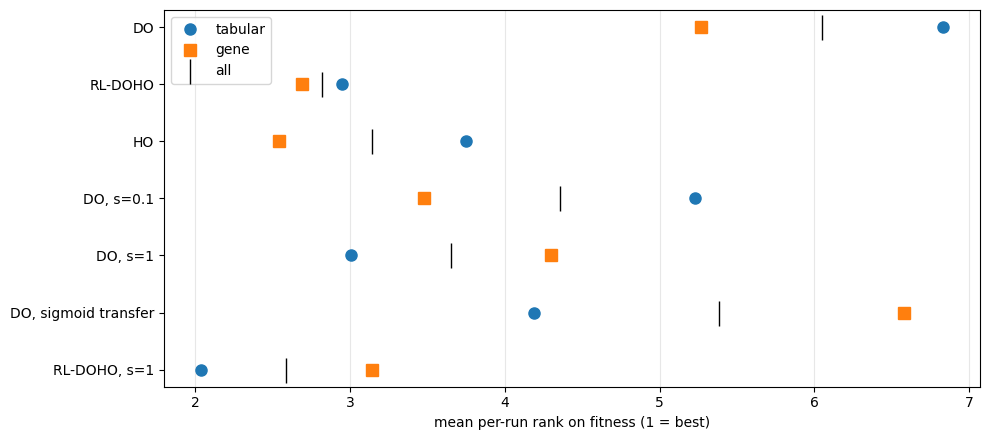

In [13]:
fig, ax = plt.subplots(figsize=(10, 4.5))
rk = mean_ranks(R, NAMES, "fit", False)
for grp, mk in (("tabular", "o"), ("gene", "s")):
    cols_g = [d for d in rk.columns if GROUP[d] == grp]
    if cols_g: ax.plot(rk[cols_g].mean(1).values, range(len(NAMES)), mk, label=grp, ms=8)
ax.plot(rk.mean(1).values, range(len(NAMES)), "k|", ms=18, label="all")
ax.set_yticks(range(len(NAMES))); ax.set_yticklabels(NAMES); ax.invert_yaxis()
ax.set_xlabel("mean per-run rank on fitness (1 = best)"); ax.legend(); ax.grid(axis="x", alpha=.3)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/v7_ranks.png", dpi=200); plt.show()

## 12. Download the results (everything except the caches and raw data)

In [14]:
zpath = f"{ROOT}/rl_doho_v7_encoding_results.zip"
with zipfile.ZipFile(zpath, "w", zipfile.ZIP_DEFLATED) as z:
    for f in sorted(os.listdir(OUT_DIR)):
        if f.startswith("cache_") or f.endswith(".tmp") or os.path.isdir(f"{OUT_DIR}/{f}"): continue
        z.write(f"{OUT_DIR}/{f}", f"rl_doho_results_v7_encoding/{f}")
print("Wrote", zpath, f"({os.path.getsize(zpath) / 1e6:.1f} MB)")
if IN_COLAB:
    from google.colab import files
    files.download(zpath)

Wrote /content/drive/MyDrive/rl_doho_v7_encoding_results.zip (0.7 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 13. How to read the outcome
- **If H12a–c all favour RL-DOHO:** the 103-of-110 result against DO does not depend on DO's encoding or step size.
- **If a DO variant closes the gap:** DO's weakness in the paper is partly due to the encoding, and the paper says so. The comparison that then carries the claim is H12d, RL-DOHO vs DO with the same larger step, together with the layer-on-HO result (H6), which does not involve DO at all.

Report all four H12 results in every case, as with H1–H11.